# 使用DBSCAN聚类算法进行聚类，然后可视化和评估效果
# 对比不同聚类算法的聚类效果，适用情形
V1.0 2023-5-25

V2.0 2024-5-27

**Installing and Importing Required Modules**

In [1]:
# importing the required modules

# !pip install kneed
!pip install scikit-learn-extra

import random
import numpy as np
# from kneed import KneeLocator
import matplotlib.pyplot as plt

from sklearn.cluster import Birch # birch
from sklearn.cluster import DBSCAN # dbscan
from sklearn.cluster import KMeans # kmeans
from sklearn_extra.cluster import KMedoids # k-medoids
from sklearn.cluster import AgglomerativeClustering # agnes

from sklearn import datasets
from sklearn.datasets import make_blobs # make_blobs
from sklearn.datasets import make_moons # make_moons
from sklearn.datasets import make_circles # make_circles

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import silhouette_score
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics.cluster import normalized_mutual_info_score

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

# 以鸢尾花数据集为例，进行DBSCAN聚类

In [2]:
# 加载数据集
iris = datasets.load_iris()
data = iris.data
target = iris.target

In [3]:
data

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

In [4]:
# 使用 DBSCAN 进行聚类
#db = DBSCAN(eps=0.1, min_samples=3) #eps取值范围(0,1)
#db.fit(data)

In [5]:
# 使用 DBSCAN 进行聚类
#db = DBSCAN(eps=0.9, min_samples=6) #eps=0.1，min_samples=6
#db.fit(data)

In [6]:
# 使用 DBSCAN 进行聚类
db = DBSCAN(eps=0.6, min_samples=4) #eps=0.6，min_samples=4
db.fit(data)

,eps,0.6
,min_samples,4
,metric,'euclidean'
,metric_params,None
,algorithm,'auto'
,leaf_size,30
,p,None
,n_jobs,None


In [7]:
# 获取聚类标签
labels = db.labels_
labels

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  1,
        1,  1,  1,  1,  1,  1,  2,  1,  1,  2,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  2,  1,  1,  1,  1,  2,  1,  1,  1,
        1,  1,  1,  1, -1,  1,  1, -1,  1,  1,  1,  1,  1,  1,  1, -1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1])

In [8]:
# 计算轮廓系数
score = silhouette_score(data, labels)
print('轮廓系数:', score)

轮廓系数: 0.423002591790791


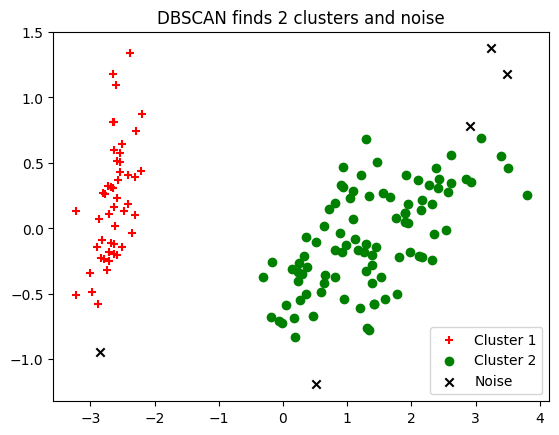

In [9]:
# 为了可视化，我们可以通过 PCA 将数据降到二维
pca = PCA(n_components=2).fit(data)
pca_2d = pca.transform(data)

# 可视化结果
for i in range(0, pca_2d.shape[0]):
    if db.labels_[i] == 0:
        c1 = plt.scatter(pca_2d[i, 0], pca_2d[i, 1], c='r', marker='+')
    elif db.labels_[i] == 1:
        c2 = plt.scatter(pca_2d[i, 0], pca_2d[i, 1], c='g', marker='o')
    elif db.labels_[i] == -1:
        c3 = plt.scatter(pca_2d[i, 0], pca_2d[i, 1], c='k', marker='x')
   

plt.legend([c1, c2, c3], ['Cluster 1', 'Cluster 2','Noise'])
plt.title('DBSCAN finds 2 clusters and noise')
plt.show()

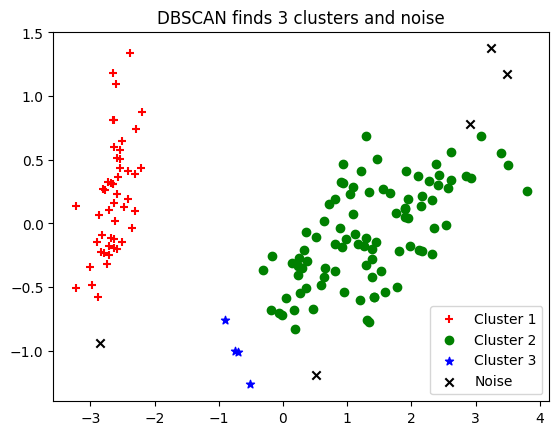

In [10]:
# 为了可视化，我们可以通过 PCA 将数据降到二维
pca = PCA(n_components=2).fit(data)
pca_2d = pca.transform(data)

# 可视化结果
for i in range(0, pca_2d.shape[0]):
    if db.labels_[i] == 0:
        c1 = plt.scatter(pca_2d[i, 0], pca_2d[i, 1], c='r', marker='+')
    elif db.labels_[i] == 1:
        c2 = plt.scatter(pca_2d[i, 0], pca_2d[i, 1], c='g', marker='o')
    elif db.labels_[i] == 2:
        c3 = plt.scatter(pca_2d[i, 0], pca_2d[i, 1], c='b', marker='*')
    elif db.labels_[i] == -1:
        c4 = plt.scatter(pca_2d[i, 0], pca_2d[i, 1], c='k', marker='x')

plt.legend([c1, c2, c3,c4], ['Cluster 1', 'Cluster 2',  'Cluster 3','Noise'])
plt.title('DBSCAN finds 3 clusters and noise')
plt.show()

## 使用k-距离图选择合适的eps参数

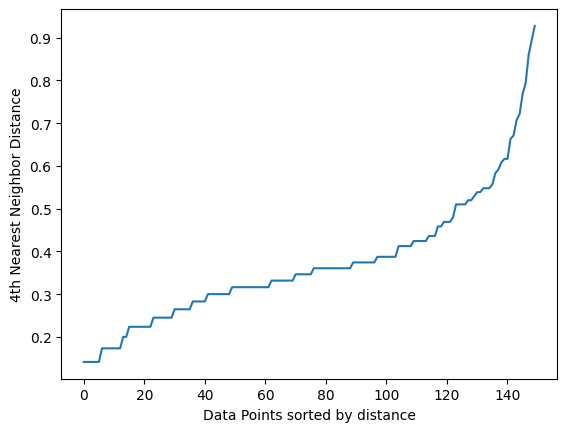

In [11]:
# 在进行DBSCAN之前，我们可以利用K-距离图选择一个合适的eps
neigh = NearestNeighbors(n_neighbors=4)
nbrs = neigh.fit(data)
distances, indices = nbrs.kneighbors(data)

distances = np.sort(distances[:,3], axis=0)
#distances = distances[:,1]
plt.plot(distances)
plt.xlabel('Data Points sorted by distance')
plt.ylabel('4th Nearest Neighbor Distance')
plt.show()

# 从图中找到最大曲率的点，对应的就是一个合适的eps

In [12]:
# 根据k-距离图选择合适的eps值
eps_value = 0.5  # 需要根据k-距离图的“肘部”选择

In [13]:
# 使用 DBSCAN 进行聚类
db = DBSCAN(eps=0.5, min_samples=4) #eps=0.5，min_samples=4
db.fit(data)

,eps,0.5
,min_samples,4
,metric,'euclidean'
,metric_params,None
,algorithm,'auto'
,leaf_size,30
,p,None
,n_jobs,None


In [14]:
# 获取聚类标签
labels = db.labels_
labels

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  1,
        1,  1,  1,  1,  1,  1,  2,  1,  1,  2,  1,  1,  1,  1,  1,  1,  1,
       -1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1, -1,  1,  1,  1,  1,  1,  2,  1,  1,  1,  1,  2,  1,  1,  1,
        1,  1,  1, -1, -1,  1, -1, -1,  1,  1,  1,  1,  1,  1,  1, -1, -1,
        1,  1,  1, -1,  1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1, -1, -1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1])

In [15]:
# 计算轮廓系数
score = silhouette_score(data, labels)
print('轮廓系数:', score)

轮廓系数: 0.38124539908253163


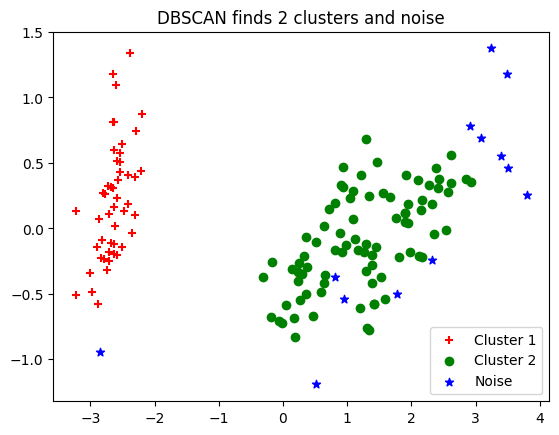

In [16]:
# 为了可视化，我们可以通过 PCA 将数据降到二维
pca = PCA(n_components=2).fit(data)
pca_2d = pca.transform(data)

# 可视化结果
for i in range(0, pca_2d.shape[0]):
    if db.labels_[i] == 0:
        c1 = plt.scatter(pca_2d[i, 0], pca_2d[i, 1], c='r', marker='+')
    elif db.labels_[i] == 1:
        c2 = plt.scatter(pca_2d[i, 0], pca_2d[i, 1], c='g', marker='o')
    elif db.labels_[i] == -1:
        c3 = plt.scatter(pca_2d[i, 0], pca_2d[i, 1], c='b', marker='*')

plt.legend([c1, c2, c3], ['Cluster 1', 'Cluster 2', 'Noise'])
plt.title('DBSCAN finds 2 clusters and noise')
plt.show()

# Comparison of different clustering algorithms

## Generating Synthetic Datasets and True Labels

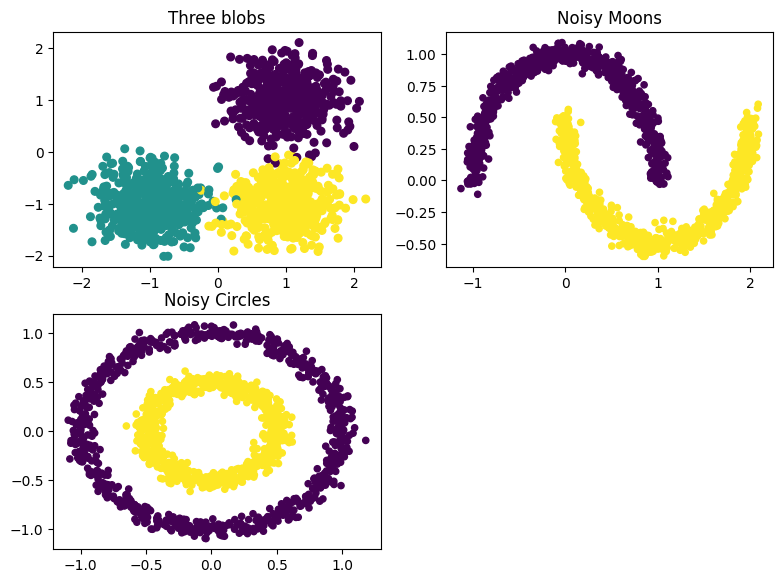

In [17]:
# generating datasets and true labels

plt.figure(figsize=(8, 8))
plt.subplots_adjust(bottom=.0005, top=1, left=.05, right=.95)

# make_blobs
plt.subplot(321)
plt.title("Three blobs", fontsize='large')
centers = [[1, 1], [-1, -1], [1, -1]]
features, labels_true = make_blobs(n_samples=1500, centers=centers, cluster_std=0.4, random_state=0)
plt.scatter(features[:, 0], features[:, 1], marker='o', c=labels_true, s=30)

# make_moons with noise
plt.subplot(322)
plt.title("Noisy Moons", fontsize='large')
features_make_moons, labels_true_make_moons = make_moons(n_samples=1500, noise=.05)
plt.scatter(features_make_moons[:, 0], features_make_moons[:, 1], marker='o', c=labels_true_make_moons, s=20)

# make_circles with noise
plt.subplot(323)
plt.title("Noisy Circles", fontsize='large')
features_make_circles, labels_true_make_circles = make_circles(n_samples=1500, factor=.5, noise=.05)
plt.scatter(features_make_circles[:, 0], features_make_circles[:, 1], marker='o', c=labels_true_make_circles, s=20)

plt.show()

**Standardization Of The Datasets**

In [18]:
# standardization of dataset

scaler = StandardScaler()

# make_bolbs
scaled_features = scaler.fit_transform(features)

# make_moons
scaled_features_make_moons = scaler.fit_transform(features_make_moons)

# make_circles
scaled_features_make_circles = scaler.fit_transform(features_make_circles)

**Instantiating Clustering Algorithms**

In [19]:
# Instantiating clustering class

# kmeans
kmeans = KMeans(init="random", n_clusters=3, n_init=50, max_iter=1500, random_state=42)
kmeans_make_moons = KMeans(init="random", n_clusters=2, n_init=50, max_iter=1500, random_state=42)
kmeans_make_circles = KMeans(init="random", n_clusters=2, n_init=50, max_iter=1500, random_state=42)

# kmedoids
kmedoids = KMedoids(n_clusters=3, init='k-medoids++', max_iter=1500, random_state=0)
kmedoids_make_moons = KMedoids(n_clusters=2, init='k-medoids++', max_iter=1500, random_state=0)
kmedoids_make_circles = KMedoids(n_clusters=2, init='k-medoids++', max_iter=1500, random_state=0)

# agnes
agnes = AgglomerativeClustering(linkage='average', n_clusters=3)
agnes_make_moons = AgglomerativeClustering(linkage='average', n_clusters=2)
agnes_make_circles = AgglomerativeClustering(linkage='average', n_clusters=2)

# dbscan
dbscan =  DBSCAN(eps=0.3, min_samples=20)
dbscan_make_moons =  DBSCAN(eps=0.3, min_samples=10)
dbscan_make_circles =  DBSCAN(eps=0.3, min_samples=10)

# birch
birch =  Birch(n_clusters=3)
birch_make_moons =  Birch(n_clusters=2)
birch_make_circles =  Birch(n_clusters=2)

**Fitting The Datasets To Clustering Algorithms**

In [20]:
# fitting the dataset to clustering class

# kmeans
kmeans.fit(scaled_features)
kmeans_make_moons.fit(scaled_features_make_moons)
kmeans_make_circles.fit(scaled_features_make_circles)

# kmedoids
kmedoids.fit(scaled_features)
kmedoids_make_moons.fit(scaled_features_make_moons)
kmedoids_make_circles.fit(scaled_features_make_circles)

# agnes
agnes.fit(scaled_features)
agnes_make_moons.fit(scaled_features_make_moons)
agnes_make_circles.fit(scaled_features_make_circles)

# dbscan
dbscan.fit(scaled_features)
core_samples_mask = np.zeros_like(dbscan.labels_, dtype=bool)
core_samples_mask[dbscan.core_sample_indices_] = True
labels = dbscan.labels_
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

dbscan_make_moons.fit(scaled_features_make_moons)
core_samples_mask_make_moons = np.zeros_like(dbscan_make_moons.labels_, dtype=bool)
core_samples_mask_make_moons[dbscan_make_moons.core_sample_indices_] = True
labels_make_moons = dbscan_make_moons.labels_
make_moons_n_clusters_ = len(set(labels_make_moons)) - (1 if -1 in labels_make_moons else 0)
make_moons_n_noise_ = list(labels_make_moons).count(-1)

dbscan_make_circles.fit(scaled_features_make_circles)
core_samples_mask_make_circles = np.zeros_like(dbscan_make_circles.labels_, dtype=bool)
core_samples_mask_make_circles[dbscan_make_circles.core_sample_indices_] = True
labels_make_circles = dbscan_make_circles.labels_
make_circles_n_clusters_ = len(set(labels_make_circles)) - (1 if -1 in labels_make_circles else 0)
make_circles_n_noise_ = list(labels_make_circles).count(-1)

# birch
birch = birch.fit(scaled_features)
birch_labels = birch.predict(scaled_features)
birch_make_moons = birch_make_moons.fit(scaled_features_make_moons)
birch_make_moons_labels = birch_make_moons.predict(scaled_features_make_moons)
birch_make_circles = birch_make_circles.fit(scaled_features_make_circles)
birch_make_circles_labels = birch_make_circles.predict(scaled_features_make_circles)

**The Data and Clusters Plotting - Blobs Dataset**

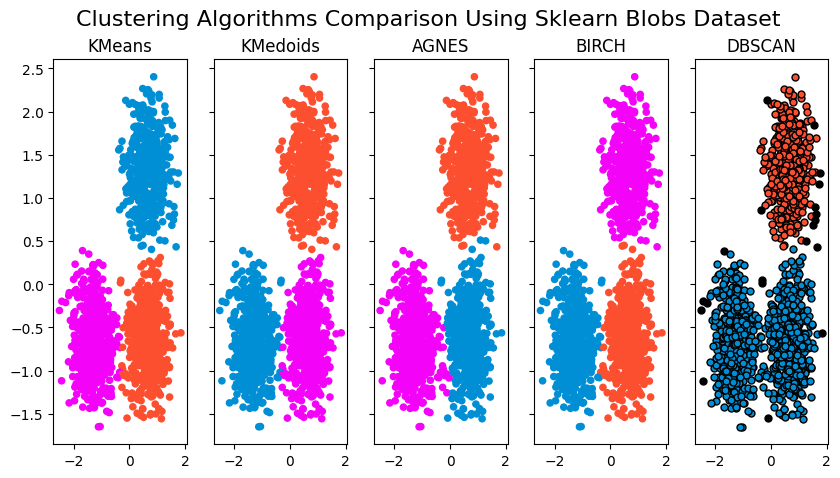

In [23]:
# Plot the data and cluster

fig, (kmeans_ax, kmedoids_ax, agnes_ax, birch_ax, dbscan_ax) = plt.subplots(1, 5, figsize=(10, 5), sharex=True, sharey=True)
fig.suptitle(f"Clustering Algorithms Comparison Using Sklearn Blobs Dataset", fontsize=16)
fte_colors = {0: "#008fd5", 1: "#fc4f30", 2: "#f304f8"}

# kmeans
kmeans_colors = [fte_colors[label] for label in kmeans.labels_]
kmeans_ax.scatter(scaled_features[:, 0], scaled_features[:, 1], c=kmeans_colors, s=20)  
kmeans_ax.set_title('KMeans')

# kmedoids
kmedoids_colors = [fte_colors[label] for label in kmedoids.labels_]
kmedoids_ax.scatter(scaled_features[:, 0], scaled_features[:, 1], c=kmedoids_colors, s=20)
kmedoids_ax.set_title('KMedoids')

# agnes
agnes_colors = [fte_colors[label] for label in agnes.labels_]
agnes_ax.scatter(scaled_features[:, 0], scaled_features[:, 1], c=agnes_colors, s=20)
agnes_ax.set_title('AGNES')

# birch
birch_colors = [fte_colors[label] for label in birch_labels]
birch_ax.scatter(scaled_features[:, 0], scaled_features[:, 1], c=birch_colors, s=20)
birch_ax.set_title('BIRCH')

# dbscan
# Black removed and is used for noise instead. 
unique_labels = set(labels)
colors = ["#008fd5", "#fc4f30", "#f304f8", "#000000"]
#colors = ['r', 'g', 'y', 'b']
for k, col in zip(unique_labels, colors): 
    if k == -1: 
        # Black used for noise. 
        col = 'k'
    class_member_mask = (labels == k) 
    
    xy = scaled_features[class_member_mask & core_samples_mask] 
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=col, 
                                      markeredgecolor='k',  
                                      markersize=5) 
    xy = scaled_features[class_member_mask & ~core_samples_mask] 
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=col, 
                                      markeredgecolor='k', 
                                      markersize=5) 

dbscan_ax.set_title('DBSCAN') 
plt.show()

**The Evaluating Metrics - Blobs Dataset**

In [22]:
kmeans_silhouette = silhouette_score(scaled_features, kmeans.labels_).round(2)
print('KMeans Blobs Dataset Silhouette Score: ', kmeans_silhouette)
ari_kmeans = adjusted_rand_score(labels_true, kmeans.labels_)
ari_kmeans = round(ari_kmeans, 2)
print('KMeans Blobs Dataset Adjusted Rand Index (ARI) Score: ', ari_kmeans)
nmi_kmeans = normalized_mutual_info_score(labels_true, kmeans.labels_)
nmi_kmeans = round(nmi_kmeans, 2)
print('KMeans Bolbs Dataset Normalized Mutual Information (NMI) Score: ', nmi_kmeans)

kmedoids_silhouette = silhouette_score(scaled_features, kmedoids.labels_).round(2)
print('\nKMedoids Blobs Dataset Silhouette Score: ', kmedoids_silhouette)
ari_kmedoids = adjusted_rand_score(labels_true, kmedoids.labels_)
ari_kmedoids = round(ari_kmedoids, 2)
print('KMedoids Blobs Dataset Adjusted Rand Index (ARI) Score: ', ari_kmedoids)
nmi_kmedoids = normalized_mutual_info_score(labels_true, kmedoids.labels_)
nmi_kmedoids = round(nmi_kmedoids, 2)
print('KMedoids Bolbs Dataset Normalized Mutual Information (NMI) Score: ', nmi_kmedoids)

agnes_silhouette = silhouette_score(scaled_features, agnes.labels_).round(2)
print('\nAGNES Blobs Dataset Silhouette Score: ', agnes_silhouette)
ari_agnes = adjusted_rand_score(labels_true, agnes.labels_)
ari_agnes = round(ari_agnes, 2)
print('AGNES Blobs Dataset Adjusted Rand Index (ARI) Score: ', ari_agnes)
nmi_agnes = normalized_mutual_info_score(labels_true, agnes.labels_)
nmi_agnes = round(nmi_agnes, 2)
print('AGNES Bolbs Dataset Normalized Mutual Information (NMI) Score: ', nmi_agnes)

birch_silhouette = silhouette_score(scaled_features, birch_labels).round(2)
print('\nBIRCH Blobs Dataset Silhouette Score: ', birch_silhouette)
ari_birch = adjusted_rand_score(labels_true, birch_labels)
ari_birch = round(ari_birch, 2)
print('BIRCH Blobs Dataset Adjusted Rand Index (ARI) Score: ', ari_birch)
nmi_birch = normalized_mutual_info_score(labels_true, birch_labels)
nmi_birch = round(nmi_birch, 2)
print('BIRCH Bolbs Dataset Normalized Mutual Information (NMI) Score: ', nmi_birch)

dbscan_silhouette = silhouette_score(scaled_features, dbscan.labels_).round(2)
print('\nDBSCAN Blobs Dataset Silhouette Score: ', dbscan_silhouette)
ari_dbscan = adjusted_rand_score(labels_true, dbscan.labels_)
ari_dbscan = round(ari_dbscan, 2)
print('DBSCAN Blobs Dataset Adjusted Rand Index (ARI) Score: ', ari_dbscan)
nmi_dbscan = normalized_mutual_info_score(labels_true, dbscan.labels_)
nmi_dbscan = round(nmi_dbscan, 2)
print('DBSCAN Bolbs Dataset Normalized Mutual Information (NMI) Score: ', nmi_dbscan)

AttributeError: 'float' object has no attribute 'round'

**The Data and Clusters Plotting - Moons Dataset**

In [ ]:
# Plot the data and cluster

fig, (kmeans_ax, kmedoids_ax, agnes_ax, birch_ax, dbscan_ax) = plt.subplots(1, 5, figsize=(12, 5), sharex=True, sharey=True)
fig.suptitle(f"Clustering Algorithms Comparison Using Sklearn Moons Dataset", fontsize=16)
fte_colors = {0: "#008fd5", 1: "#fc4f30", 2: "#f304f8"}

# kmeans
kmeans_colors = [fte_colors[label] for label in kmeans_make_moons.labels_]
kmeans_ax.scatter(scaled_features_make_moons[:, 0], scaled_features_make_moons[:, 1], c=kmeans_colors,s=10)
kmeans_ax.set_title('KMeans')

# kmedoids
kmedoids_colors = [fte_colors[label] for label in kmedoids_make_moons.labels_]
kmedoids_ax.scatter(scaled_features_make_moons[:, 0], scaled_features_make_moons[:, 1], c=kmedoids_colors,s=10)
kmedoids_ax.set_title('KMedoids')

# agnes
agnes_colors = [fte_colors[label] for label in agnes_make_moons.labels_]
agnes_ax.scatter(scaled_features_make_moons[:, 0], scaled_features_make_moons[:, 1], c=agnes_colors,s=10)
agnes_ax.set_title('AGNES')

# birch
birch_colors = [fte_colors[label] for label in birch_make_moons_labels]
birch_ax.scatter(scaled_features_make_moons[:, 0], scaled_features_make_moons[:, 1], c=birch_colors,s=10)
birch_ax.set_title('BIRCH')

# dbscan
# Black removed and is used for noise instead. 
unique_labels = set(labels_make_moons)
colors = ["#008fd5", "#fc4f30", "#f304f8", "#000000"]
for k, col in zip(unique_labels, colors): 
    if k == -1: 
        # Black used for noise. 
        col = 'k'
    class_member_mask = (labels_make_moons == k) 
    xy = scaled_features_make_moons[class_member_mask & core_samples_mask] 
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=col, 
                                      markeredgecolor='k',  
                                      markersize=6) 
    xy = scaled_features_make_moons[class_member_mask & ~core_samples_mask] 
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=col, 
                                      markeredgecolor='k', 
                                      markersize=6) 
dbscan_ax.set_title('DBSCAN') 
plt.show()

#plt.show()

**The Evaluating Metrics - Moons Dataset**

In [ ]:
kmeans_silhouette_make_moons = silhouette_score(scaled_features_make_moons, kmeans_make_moons.labels_).round(2)
print('KMeans Moons Dataset Silhouette Score: ', kmeans_silhouette_make_moons)
ari_kmeans_make_moons = adjusted_rand_score(labels_true_make_moons, kmeans_make_moons.labels_)
ari_kmeans_make_moons = round(ari_kmeans_make_moons, 2)
print('KMeans Moons Dataset Adjusted Rand Index (ARI) Score: ', ari_kmeans_make_moons)
nmi_kmeans_make_moons = normalized_mutual_info_score(labels_true_make_moons, kmeans_make_moons.labels_)
nmi_kmeans_make_moons = round(nmi_kmeans_make_moons, 2)
print('KMeans Moons Dataset Normalized Mutual Information (NMI) Score: ', nmi_kmeans_make_moons)

kmedoids_silhouette_make_moons = silhouette_score(scaled_features_make_moons, kmedoids_make_moons.labels_).round(2)
print('\nKMedoids Moons Dataset Silhouette Score: ', kmedoids_silhouette_make_moons)
ari_kmedoids_make_moons = adjusted_rand_score(labels_true_make_moons, kmedoids_make_moons.labels_)
ari_kmedoids_make_moons = round(ari_kmedoids_make_moons, 2)
print('KMedoids Moons Dataset Adjusted Rand Index (ARI) Score: ', ari_kmedoids_make_moons)
nmi_kmedoids_make_moons = normalized_mutual_info_score(labels_true_make_moons, kmedoids_make_moons.labels_)
nmi_kmedoids_make_moons = round(nmi_kmedoids_make_moons, 2)
print('KMedoids Moons Dataset Normalized Mutual Information (NMI) Score: ', nmi_kmedoids_make_moons)


agnes_silhouette_make_moons = silhouette_score(scaled_features_make_moons, agnes_make_moons.labels_).round(2)
print('\nAGNES Moons Dataset Silhouette Score: ', agnes_silhouette_make_moons)
ari_agnes_make_moons = adjusted_rand_score(labels_true_make_moons, agnes_make_moons.labels_)
ari_agnes_make_moons = round(ari_agnes_make_moons, 2)
print('AGNES Moons Dataset Adjusted Rand Index (ARI) Score: ', ari_agnes_make_moons)
nmi_agnes_make_moons = normalized_mutual_info_score(labels_true_make_moons, agnes_make_moons.labels_)
nmi_agnes_make_moons = round(nmi_agnes_make_moons, 2)
print('AGNES Moons Dataset Normalized Mutual Information (NMI) Score: ', nmi_agnes_make_moons)

birch_silhouette_make_moons = silhouette_score(scaled_features_make_moons, birch_make_moons_labels).round(2)
print('\nBIRCH Moons Dataset Silhouette Score: ', birch_silhouette_make_moons)
ari_birch_make_moons = adjusted_rand_score(labels_true_make_moons, birch_make_moons_labels)
ari_birch_make_moons = round(ari_birch_make_moons, 2)
print('BIRCH Moons Dataset Adjusted Rand Index (ARI) Score: ', ari_birch_make_moons)
nmi_birch_make_moons = normalized_mutual_info_score(labels_true_make_moons, birch_make_moons_labels)
nmi_birch_make_moons = round(nmi_birch_make_moons, 2)
print('BIRCH Moons Dataset Normalized Mutual Information (NMI) Score: ', nmi_birch_make_moons)

dbscan_silhouette_make_moons = silhouette_score(scaled_features_make_moons, dbscan_make_moons.labels_).round(2)
print('\nDBSCAN Moons Dataset Silhouette Score: ', dbscan_silhouette_make_moons)
ari_dbscan_make_moons = adjusted_rand_score(labels_true_make_moons, dbscan_make_moons.labels_)
ari_dbscan_make_moons = round(ari_dbscan_make_moons, 2)
print('DBSCAN Moons Dataset Adjusted Rand Index (ARI) Score: ', ari_dbscan_make_moons)
nmi_dbscan_make_moons = normalized_mutual_info_score(labels_true_make_moons, dbscan_make_moons.labels_)
nmi_dbscan_make_moons = round(nmi_dbscan_make_moons, 2)
print('DBSCAN Moons Dataset Normalized Mutual Information (NMI) Score: ', nmi_dbscan_make_moons)

**The Data and Clusters Plotting - Circles Dataset**

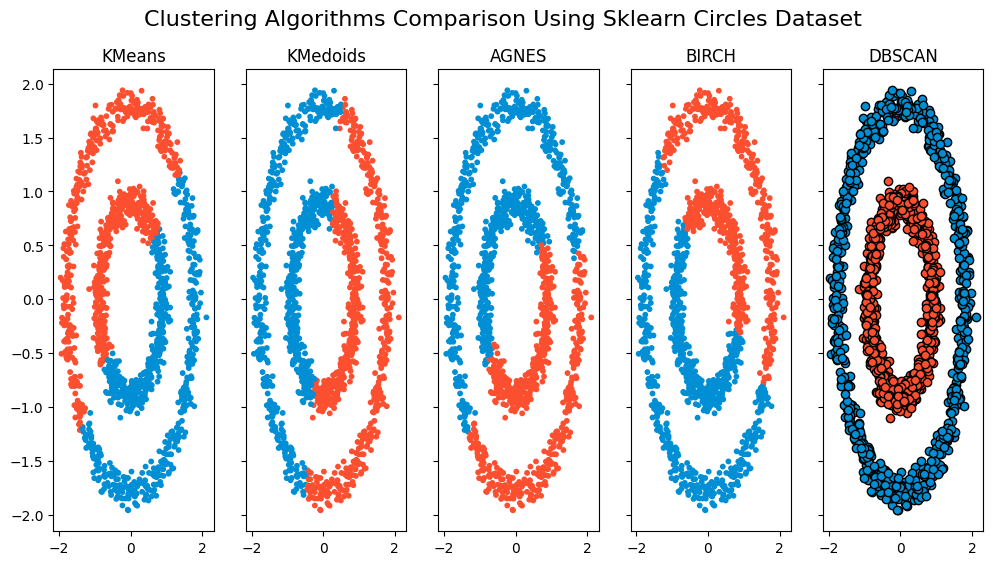

AttributeError: module 'matplotlib.pyplot' has no attribute 'imgsave'

In [24]:
# Plot the data and cluster

fig, (kmeans_ax, kmedoids_ax, agnes_ax, birch_ax, dbscan_ax) = plt.subplots(1, 5, figsize=(12, 6), sharex=True, sharey=True)
fig.suptitle(f"Clustering Algorithms Comparison Using Sklearn Circles Dataset", fontsize=16)
fte_colors = {0: "#008fd5", 1: "#fc4f30", 2: "#f304f8"}

# kmeans
kmeans_colors = [fte_colors[label] for label in kmeans_make_circles.labels_]
kmeans_ax.scatter(scaled_features_make_circles[:, 0], scaled_features_make_circles[:, 1], c=kmeans_colors,s=10)
kmeans_ax.set_title('KMeans')

# kmedoids
kmedoids_colors = [fte_colors[label] for label in kmedoids_make_circles.labels_]
kmedoids_ax.scatter(scaled_features_make_circles[:, 0], scaled_features_make_circles[:, 1], c=kmedoids_colors,s=10)
kmedoids_ax.set_title('KMedoids')

# agnes
agnes_colors = [fte_colors[label] for label in agnes_make_circles.labels_]
agnes_ax.scatter(scaled_features_make_circles[:, 0], scaled_features_make_circles[:, 1], c=agnes_colors,s=10)
agnes_ax.set_title('AGNES')

# birch
birch_colors = [fte_colors[label] for label in birch_make_circles_labels]
birch_ax.scatter(scaled_features_make_circles[:, 0], scaled_features_make_circles[:, 1], c=birch_colors,s=10)
birch_ax.set_title('BIRCH')

# dbscan
# Black removed and is used for noise instead. 
unique_labels = set(labels_make_circles)
colors = ["#008fd5", "#fc4f30", "#f304f8", "#000000"]
for k, col in zip(unique_labels, colors): 
    if k == -1: 
        # Black used for noise. 
        col = 'k'
    class_member_mask = (labels_make_circles == k) 
    xy = scaled_features_make_circles[class_member_mask & core_samples_mask] 
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=col, 
                                      markeredgecolor='k',  
                                      markersize=6) 
    xy = scaled_features_make_circles[class_member_mask & ~core_samples_mask] 
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=col, 
                                      markeredgecolor='k', 
                                      markersize=6) 
dbscan_ax.set_title('DBSCAN') 
plt.show()
plt.imgsave("1.jpg")

**The Evaluating Metrics - Circles Dataset**

In [ ]:
kmeans_silhouette_make_circles = silhouette_score(scaled_features_make_circles, kmeans_make_circles.labels_).round(2)
print('KMeans Circles Dataset Silhouette Score: ', kmeans_silhouette_make_circles)
ari_kmeans_make_circles = adjusted_rand_score(labels_true_make_circles, kmeans_make_circles.labels_)
ari_kmeans_make_circles = round(ari_kmeans_make_circles, 2)
print('KMeans Circles Dataset Adjusted Rand Index (ARI) Score: ', ari_kmeans_make_circles)
nmi_kmeans_make_circles = normalized_mutual_info_score(labels_true_make_circles, kmeans_make_circles.labels_)
nmi_kmeans_make_circles = round(nmi_kmeans_make_circles, 2)
print('KMeans Circles Dataset Normalized Mutual Information (NMI) Score: ', nmi_kmeans_make_circles)

kmedoids_silhouette_make_circles = silhouette_score(scaled_features_make_circles, kmedoids_make_circles.labels_).round(2)
print('\nKMedoids Circles Dataset Silhouette Score: ', kmedoids_silhouette_make_circles)
ari_kmedoids_make_circles = adjusted_rand_score(labels_true_make_circles, kmedoids_make_circles.labels_)
ari_kmedoids_make_circles = round(ari_kmedoids_make_circles, 2)
print('KMedoids Circles Dataset Adjusted Rand Index (ARI) Score: ', ari_kmedoids_make_circles)
nmi_kmedoids_make_circles = normalized_mutual_info_score(labels_true_make_circles, kmedoids_make_circles.labels_)
nmi_kmedoids_make_circles = round(nmi_kmedoids_make_circles, 2)
print('KMedoids Circles Dataset Normalized Mutual Information (NMI) Score: ', nmi_kmedoids_make_circles)

agnes_silhouette_make_circles = silhouette_score(scaled_features_make_circles, agnes_make_circles.labels_).round(2)
print('\nAGNES Circles Dataset Silhouette Score: ', agnes_silhouette_make_circles)
ari_agnes_make_circles = adjusted_rand_score(labels_true_make_circles, agnes_make_circles.labels_)
ari_agnes_make_circles = round(ari_agnes_make_circles, 2)
print('AGNES Circles Dataset Adjusted Rand Index (ARI) Score: ', ari_agnes_make_circles)
nmi_agnes_make_circles = normalized_mutual_info_score(labels_true_make_circles, agnes_make_circles.labels_)
nmi_agnes_make_circles = round(nmi_agnes_make_circles, 2)
print('AGNES Circles Dataset Normalized Mutual Information (NMI) Score: ', nmi_agnes_make_circles)

birch_silhouette_make_circles = silhouette_score(scaled_features_make_circles, birch_make_circles_labels).round(2)
print('\nBIRCH Circles Dataset Silhouette Score: ', birch_silhouette_make_circles)
ari_birch_make_circles = adjusted_rand_score(labels_true_make_circles, birch_make_circles_labels)
ari_birch_make_circles = round(ari_birch_make_circles, 2)
print('BIRCH Circles Dataset Adjusted Rand Index (ARI) Score: ', ari_birch_make_circles)
nmi_birch_make_circles = normalized_mutual_info_score(labels_true_make_circles, birch_make_circles_labels)
nmi_birch_make_circles = round(nmi_birch_make_circles, 2)
print('BIRCH Circles Dataset Normalized Mutual Information (NMI) Score: ', nmi_birch_make_circles)

dbscan_silhouette_make_circles = silhouette_score(scaled_features_make_circles, dbscan_make_circles.labels_).round(2)
print('\nDBSCAN Circles Dataset Silhouette Score: ', dbscan_silhouette_make_circles)
ari_dbscan_make_circles = adjusted_rand_score(labels_true_make_circles, dbscan_make_circles.labels_)
ari_dbscan_make_circles = round(ari_dbscan_make_circles, 2)
print('DBSCAN Circles Dataset Adjusted Rand Index (ARI) Score: ', ari_dbscan_make_circles)
nmi_dbscan_make_circles = normalized_mutual_info_score(labels_true_make_circles, dbscan_make_circles.labels_)
nmi_dbscan_make_circles = round(nmi_dbscan_make_circles, 2)
print('DBSCAN Circles Dataset Normalized Mutual Information (NMI) Score: ', nmi_dbscan_make_circles)

K-Means 和 K-Medoids 适用于球形簇，前者计算快但对噪声敏感，后者对噪声更鲁棒但计算复杂度高
AGNES 和 BIRCH 适用于层次结构的探索，前者适用于小规模数据，后者适用于大规模数据。
DBSCAN 适用于任意形状簇和含有噪声的数据，但对参数敏感。